In [1]:
import pandas as pd

In [2]:
df=pd.read_csv("post_covid_data.csv")
df.head()

,Patient_ID,Age,Gender,Fever,Cough,Fatigue,Headache,Post_COVID,Recovery_Days,Chronic_Disease
0,P0001,42.0,Female,No,no,Yes,yes,Yes,18.0,No
1,P0002,NaN,Male,No,Yes,NaN,yes,No,36.0,NaN
2,P0003,66.0,Male,Yes,NaN,Yes,NaN,Yes,20.0,No
3,P0004,57.0,Male,Yes,No,Yes,Yes,Yes,34.0,No
4,P0005,28.0,Female,Yes,No,no,no,Yes,21.0,No


In [3]:
df.tail()

,Patient_ID,Age,Gender,Fever,Cough,Fatigue,Headache,Post_COVID,Recovery_Days,Chronic_Disease
739,P0698,56.0,male,Yes,no,yes,No,Yes,24.0,No
740,P0568,47.0,female,No,Yes,Yes,No,yes,38.0,Yes
741,P0306,NaN,Male,Yes,Yes,No,Yes,yes,17.0,No
742,P0480,52.0,Female,Yes,Yes,Yes,Yes,Yes,33.0,No
743,P0420,68.0,Male,Yes,Yes,Yes,no,Yes,29.0,Yes


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 744 entries, 0 to 743
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Patient_ID       744 non-null    object 
 1   Age              698 non-null    float64
 2   Gender           726 non-null    object 
 3   Fever            715 non-null    object 
 4   Cough            708 non-null    object 
 5   Fatigue          708 non-null    object 
 6   Headache         708 non-null    object 
 7   Post_COVID       719 non-null    object 
 8   Recovery_Days    737 non-null    float64
 9   Chronic_Disease  716 non-null    object 
dtypes: float64(2), object(8)
memory usage: 58.3+ KB


In [5]:
df.isnull().sum()

Patient_ID          0
Age                46
Gender             18
Fever              29
Cough              36
Fatigue            36
Headache           36
Post_COVID         25
Recovery_Days       7
Chronic_Disease    28
dtype: int64

In [6]:
df.shape

(744, 10)

In [7]:
df.duplicated().sum()

np.int64(10)

In [8]:
df[df.duplicated()]

,Patient_ID,Age,Gender,Fever,Cough,Fatigue,Headache,Post_COVID,Recovery_Days,Chronic_Disease
734,P0585,60.0,Female,Yes,NaN,No,No,Yes,9.0,No
735,P0263,27.0,Male,Yes,No,yes,NaN,Yes,37.0,No
736,P0160,66.0,Male,yes,No,No,NaN,Yes,20.0,No
737,P0403,51.0,Female,Yes,No,Yes,Yes,Yes,35.0,No
738,P0522,43.0,Male,Yes,yes,Yes,No,NaN,21.0,No
739,P0698,56.0,male,Yes,no,yes,No,Yes,24.0,No
740,P0568,47.0,female,No,Yes,Yes,No,yes,38.0,Yes
741,P0306,NaN,Male,Yes,Yes,No,Yes,yes,17.0,No
742,P0480,52.0,Female,Yes,Yes,Yes,Yes,Yes,33.0,No
743,P0420,68.0,Male,Yes,Yes,Yes,no,Yes,29.0,Yes


In [9]:
df = df.drop_duplicates()

In [10]:
df.duplicated().sum()

np.int64(0)

In [11]:
df = df.drop(columns=['Patient_ID'])

In [13]:
df.columns

Index(['Age', 'Gender', 'Fever', 'Cough', 'Fatigue', 'Headache', 'Post_COVID',
       'Recovery_Days', 'Chronic_Disease'],
      dtype='object')

In [14]:
df['Recovery_Days'] = df['Recovery_Days'].fillna(df['Recovery_Days'].mean())

In [15]:
df['Age'] = df['Age'].fillna(df['Age'].median())

In [16]:
# Fill categorical or boolean columns with mode
df['Gender'] = df['Gender'].fillna(df['Gender'].mode()[0])
df['Fever'] = df['Fever'].fillna(df['Fever'].mode()[0])
df['Cough'] = df['Cough'].fillna(df['Cough'].mode()[0])
df['Fatigue'] = df['Fatigue'].fillna(df['Fatigue'].mode()[0])
df['Headache'] = df['Headache'].fillna(df['Headache'].mode()[0])
df['Post_COVID'] = df['Post_COVID'].fillna(df['Post_COVID'].mode()[0])
df['Chronic_Disease'] = df['Chronic_Disease'].fillna(df['Chronic_Disease'].mode()[0])

In [17]:
df.isnull().sum()

Age                0
Gender             0
Fever              0
Cough              0
Fatigue            0
Headache           0
Post_COVID         0
Recovery_Days      0
Chronic_Disease    0
dtype: int64

In [32]:
df.to_csv("cleaned_post_covid_data.csv", index=False)

In [19]:
df.describe()

,Age,Recovery_Days
count,734.000000,734.000000
mean,48.348774,23.149931
std,17.933663,9.679915
min,18.000000,7.000000
25%,33.000000,14.000000
50%,49.000000,23.149931
75%,63.000000,31.000000
max,80.000000,39.000000


In [20]:
df.groupby('Gender')['Recovery_Days'].mean()
df.groupby('Chronic_Disease')['Recovery_Days'].median()

Chronic_Disease
No     23.0
Yes    25.0
no     24.0
yes    18.0
Name: Recovery_Days, dtype: float64

In [21]:
# List of categorical columns to clean
cat_cols = ['Gender', 'Chronic_Disease', 'Fever', 'Cough', 'Fatigue', 'Headache', 'Post_COVID']

# Capitalize first letter of each word (e.g. 'yes' → 'Yes')
for col in cat_cols:
    df[col] = df[col].str.strip().str.capitalize()

In [22]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [23]:
import seaborn as sns
import matplotlib.pyplot as plt

# Custom colors
colors = {
    "dark_blue": "#003f5c",
    "orange": "#ffa600",
    "green": "#2f9e44",
    "white": "#f8f9fa"
}

# Set overall theme
sns.set(style="whitegrid", font_scale=1.1)
plt.rcParams['axes.edgecolor'] = 'gray'
plt.rcParams['axes.labelcolor'] = colors["dark_blue"]
plt.rcParams['text.color'] = colors["dark_blue"]
plt.rcParams['xtick.color'] = colors["dark_blue"]
plt.rcParams['ytick.color'] = colors["dark_blue"]
plt.rcParams['axes.titleweight'] = 'bold'

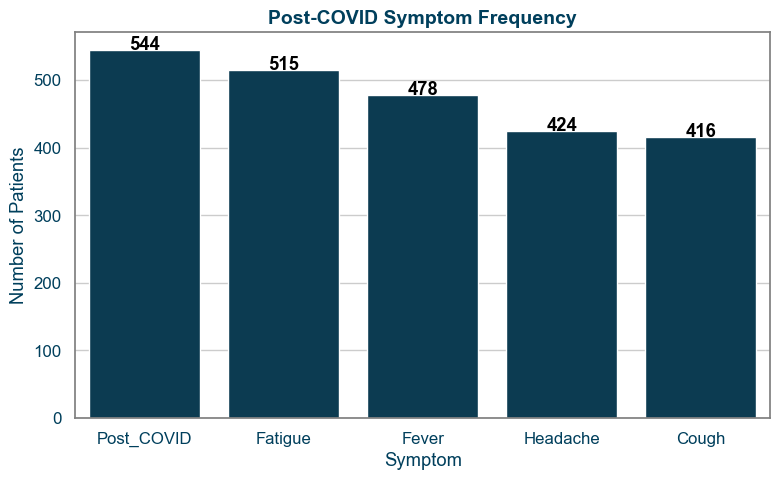

In [24]:
import matplotlib.pyplot as plt
import seaborn as sns

symptoms = ['Fever', 'Cough', 'Fatigue', 'Headache', 'Post_COVID']
symptom_counts = df[symptoms].apply(lambda x: x.str.lower().eq('yes').sum()).sort_values(ascending=False)

# Apply your cleaned version
symptom_counts = df[symptoms].apply(lambda x: x.str.capitalize().eq('Yes').sum()).sort_values(ascending=False)

# Dark blue color
dark_blue = "#003f5c"

plt.figure(figsize=(8, 5))
sns.barplot(x=symptom_counts.index, y=symptom_counts.values, color=dark_blue)
plt.title("Post-COVID Symptom Frequency", fontsize=14, fontweight='bold')
plt.xlabel("Symptom")
plt.ylabel("Number of Patients")

# Labels above bars
for index, value in enumerate(symptom_counts.values):
    plt.text(index, value + 1, str(value), ha='center', color='black', fontweight='bold')

plt.tight_layout()
plt.show()

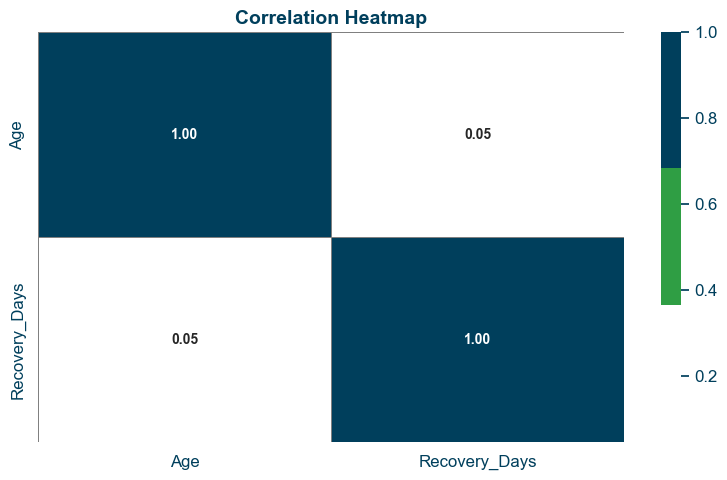

In [25]:
plt.figure(figsize=(8, 5))
sns.heatmap(df.corr(numeric_only=True), annot=True, fmt=".2f",
            cmap=sns.color_palette(["white", colors["green"], colors["dark_blue"]], as_cmap=True),
            linewidths=0.5, linecolor='gray', annot_kws={"weight": "bold", "fontsize": 10})
plt.title("Correlation Heatmap", fontsize=14)
plt.tight_layout()
plt.show()

C:\Users\hp\AppData\Local\Temp\ipykernel_10104\3573177453.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Gender', y='Recovery_Days', data=df, palette=["#003f5c", "#2f9e44"])  # Dark blue and green


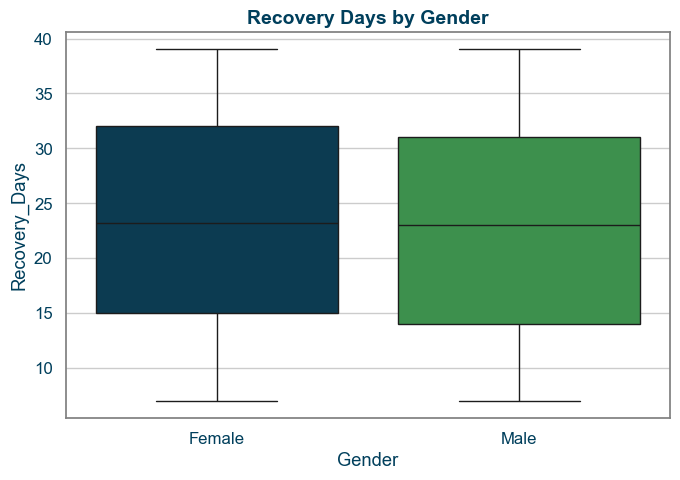

In [26]:
# Capitalize Gender to fix duplicates
df['Gender'] = df['Gender'].str.capitalize()

plt.figure(figsize=(7, 5))
sns.boxplot(x='Gender', y='Recovery_Days', data=df, palette=["#003f5c", "#2f9e44"])  # Dark blue and green
plt.title("Recovery Days by Gender", fontsize=14)
plt.tight_layout()
plt.show()

In [27]:
import pandas as pd

In [33]:
df=pd.read_csv("Cleaned_post_covid_data_original.csv")
df.head()

,Patient_ID,Age,Gender,Fever,Cough,Fatigue,Headache,Post_COVID,Recovery_Days,Chronic_Disease
0,P0001,42.0,Female,No,no,Yes,yes,Yes,18.0,No
1,P0002,49.0,Male,No,Yes,Yes,yes,No,36.0,No
2,P0003,66.0,Male,Yes,Yes,Yes,Yes,Yes,20.0,No
3,P0004,57.0,Male,Yes,No,Yes,Yes,Yes,34.0,No
4,P0005,28.0,Female,Yes,No,no,no,Yes,21.0,No


In [30]:
# Standardize the Chronic_Disease column
df['Chronic_Disease'] = df['Chronic_Disease'].str.strip().str.lower()

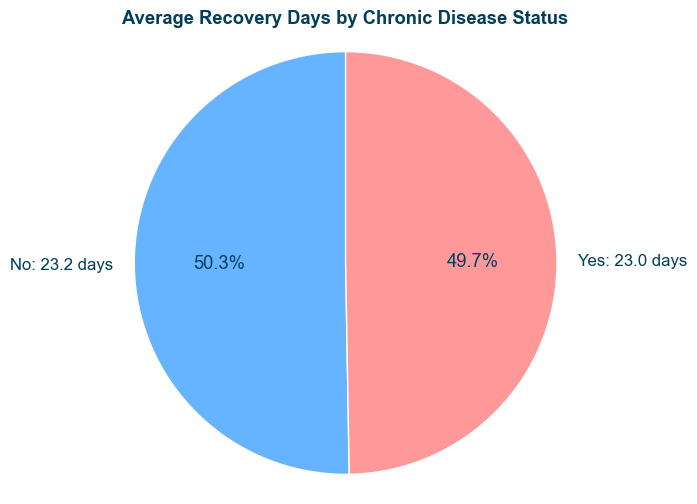

In [31]:
# Group and get mean recovery days
avg_recovery = df.groupby('Chronic_Disease')['Recovery_Days'].mean()

# Capitalize for chart labels
avg_recovery.index = avg_recovery.index.str.capitalize()

# Plot the pie chart
import matplotlib.pyplot as plt

plt.figure(figsize=(6,6))
plt.pie(
    avg_recovery,
    labels=[f"{label}: {value:.1f} days" for label, value in zip(avg_recovery.index, avg_recovery)],
    autopct='%1.1f%%',
    startangle=90,
    colors=['#66b3ff', '#ff9999']
)
plt.title('Average Recovery Days by Chronic Disease Status')
plt.axis('equal')
plt.show()